# 02 · Resampling techniques

**Projet Métier: Handling class imbalance in credit-card fraud detection**

The EDA showed that frauds are only **0.17 %** of the transactions. This notebook presents the
techniques that **rebalance the training data** before a classifier is fitted, and *visualises
what each one actually does* to the data.

**Contents**

1. Why rebalance at all?
2. The four families of strategies
3. The golden rule: resample the training data only
4. Visualising every technique on real transactions
5. Comparing the resulting datasets
6. Strengths and weaknesses of each family

In [1]:
import sys
import warnings
from pathlib import Path

# Make the project package importable whether the notebook runs from notebooks/ or the root
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from fraud_resampling.plots import set_style, LEGIT_COLOR, FRAUD_COLOR, CLASS_PALETTE, FAMILY_COLORS

set_style()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 120)

from time import perf_counter
from sklearn.preprocessing import StandardScaler
from fraud_resampling import load_data, train_test_split_stratified, SAMPLERS, get_sampler

## 1. Why rebalance at all?

Most classifiers are trained to minimise an *average* error over all training examples. When
599 out of 600 examples are legitimate, a model that mostly ignores frauds still has an excellent
average error. The fraud class contributes too little to the loss to shape the decision boundary,
which then ends up pushed against the few frauds.

Rebalancing changes this in one of two ways:

* **change the data** (resampling) so that the classifier sees a more balanced problem, or
* **change the loss** (cost-sensitive learning) so that an error on a fraud costs more than an
  error on a legitimate transaction.

## 2. The four families of strategies

| Family | Idea | Techniques studied |
|---|---|---|
| **Over-sampling** | *Add* fraud examples: copies or synthetic ones | Random Over-Sampling, SMOTE, Borderline-SMOTE, SVM-SMOTE, K-Means-SMOTE, ADASYN |
| **Under-sampling** | *Remove* legitimate examples, randomly or with a rule | Random Under-Sampling, NearMiss 1/2/3, Tomek Links, Edited Nearest Neighbours |
| **Hybrid** | Over-sample, then *clean* the overlap between classes | SMOTE + Tomek, SMOTE + ENN |
| **Cost-sensitive** (reference) | No resampling, weight the classes in the loss | `class_weight="balanced"` |

All samplers come from [imbalanced-learn](https://imbalanced-learn.org). The registry in
`fraud_resampling/samplers.py` gives each one a short description:

In [2]:
catalogue = pd.DataFrame(
    [{"technique": t.name, "family": t.family, "how it works": t.summary} for t in SAMPLERS.values()]
).set_index("technique")
catalogue.style.set_properties(**{"text-align": "left"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left")]}])

,family,how it works
technique,,
None,none,"Baseline: the model is trained on the original, imbalanced data."
Class weights,cost-sensitive,No resampling; the loss of each class is weighted by its inverse frequency (class_weight='balanced').
RandomOverSampler,over,Duplicates randomly chosen fraud transactions until both classes have the same size.
SMOTE,over,Creates synthetic frauds by interpolating between a fraud and one of its k=5 nearest fraud neighbours.
BorderlineSMOTE,over,"SMOTE restricted to 'danger' frauds, i.e. those whose neighbourhood is mostly legitimate (the decision border)."
SVMSMOTE,over,"Uses the support vectors of an SVM to locate the border, then applies SMOTE there."
KMeansSMOTE,over,Clusters the data with k-means and applies SMOTE inside clusters that contain frauds.
ADASYN,over,"Like SMOTE, but generates more samples for frauds that are harder to learn (surrounded by legitimate transactions)."
RandomUnderSampler,under,Randomly discards legitimate transactions until both classes have the same size.


### A closer look at the key ideas

**SMOTE** (Synthetic Minority Over-sampling TEchnique, Chawla et al., 2002). For a fraud $x_i$, pick one
of its $k$ nearest *fraud* neighbours $x_{nn}$ and create a new sample on the segment between them:

$$x_{new} = x_i + \lambda \,(x_{nn} - x_i), \qquad \lambda \sim \mathcal{U}(0, 1)$$

Unlike random over-sampling (exact copies), SMOTE fills the space *between* frauds. That makes the
fraud region larger and smoother and reduces over-fitting to individual points. The risk is that,
when frauds are scattered, a segment may cross a legitimate region and create implausible frauds.

**Borderline-SMOTE / SVM-SMOTE / ADASYN** focus the generation where it is most useful:
near the decision border (frauds whose neighbours are mostly legitimate, or the support vectors of an SVM),
or proportionally to how hard each fraud is to classify (ADASYN).

**NearMiss** keeps only the legitimate transactions that are *close to frauds*, under three
definitions of "close". **Tomek Links** and **ENN** are *cleaning* rules: they only remove legitimate
points that sit inside or right next to the fraud region, so the class ratio barely changes.

## 3. The golden rule: resample the training data only

Resampling is a **training trick**, not a transformation of the problem. The model will be used on
real transactions, where frauds are 0.17 %, so it must be **evaluated on untouched data**:

```
            ┌────────────── training folds ──────────────┐   ┌─ validation fold ─┐
raw data ─► │ scale ─► RESAMPLE ─► fit the classifier    │   │ scale ─► predict  │  ◄─ never resampled
            └────────────────────────────────────────────┘   └───────────────────┘
```

Resampling the whole dataset *before* splitting it (which is easy to do by accident) puts synthetic
frauds that are near-copies of training points into the validation set, and turns its class ratio into
50/50. The scores then become wildly optimistic. Notebook 03 measures exactly how much.

In code this rule is enforced by an **imbalanced-learn `Pipeline`**: its sampler step runs during
`fit` only and is skipped during `predict`.

## 4. Visualising every technique on real transactions

To *see* the effect of each technique we:

* take the **training part** of the 80/20 stratified split (the test set stays hidden until notebook 04),
* keep **all training frauds** and a random sample of **15 000 legitimate** transactions, so that the
  slow techniques run in seconds and the plots stay readable (the ratio here is ≈ 2.5 % fraud
  instead of 0.17 %),
* standardise the 30 features, resample in the **full 30-dimensional space**, then plot two of the most
  discriminative features found in the EDA: **`V14`** and **`V10`**.

In each panel, **synthetic** frauds are shown in green and **removed** legitimate transactions in light grey.

In [3]:
df = load_data()
X_train, X_test, y_train, y_test = train_test_split_stratified(df)
print(f"Training set: {len(y_train):,} rows, {y_train.sum()} frauds | test set (kept aside): {len(y_test):,} rows")

legit_idx = y_train[y_train == 0].sample(15_000, random_state=42).index
demo_idx = legit_idx.union(y_train[y_train == 1].index)
X_demo = StandardScaler().fit_transform(X_train.loc[demo_idx])
y_demo = y_train.loc[demo_idx].to_numpy()
print(f"Demo subset: {len(y_demo):,} rows, {y_demo.sum()} frauds ({y_demo.mean():.2%})")

FX, FY = list(X_train.columns).index("V14"), list(X_train.columns).index("V10")

Training set: 226,980 rows, 378 frauds | test set (kept aside): 56,746 rows
Demo subset: 15,378 rows, 378 frauds (2.46%)


In [4]:
def row_keys(X):
    return np.array([row.tobytes() for row in np.ascontiguousarray(X)])

original_keys = row_keys(X_demo)
original_set = set(original_keys)

resampled, rows = {}, []
for name, technique in SAMPLERS.items():
    if technique.factory is None:          # "None" and "Class weights" do not resample
        continue
    start = perf_counter()
    X_res, y_res = get_sampler(name).fit_resample(X_demo, y_demo)
    elapsed = perf_counter() - start

    res_keys = row_keys(X_res)
    res_set = set(res_keys)
    synthetic = np.array([k not in original_set for k in res_keys])  # rows that did not exist before
    removed = np.array([k not in res_set for k in original_keys])     # original rows that disappeared
    resampled[name] = (X_res, y_res, synthetic, removed)
    rows.append({
        "technique": name, "family": technique.family,
        "legit": int((y_res == 0).sum()), "fraud": int((y_res == 1).sum()),
        "fraud share (%)": y_res.mean() * 100,
        "synthetic frauds": int(synthetic.sum()),
        "duplicated frauds": int((y_res == 1).sum() - synthetic.sum() - (y_demo == 1).sum()
                                 + (removed & (y_demo == 1)).sum()),
        "removed legit": int((removed & (y_demo == 0)).sum()),
        "time (s)": elapsed,
    })
print("done")

done


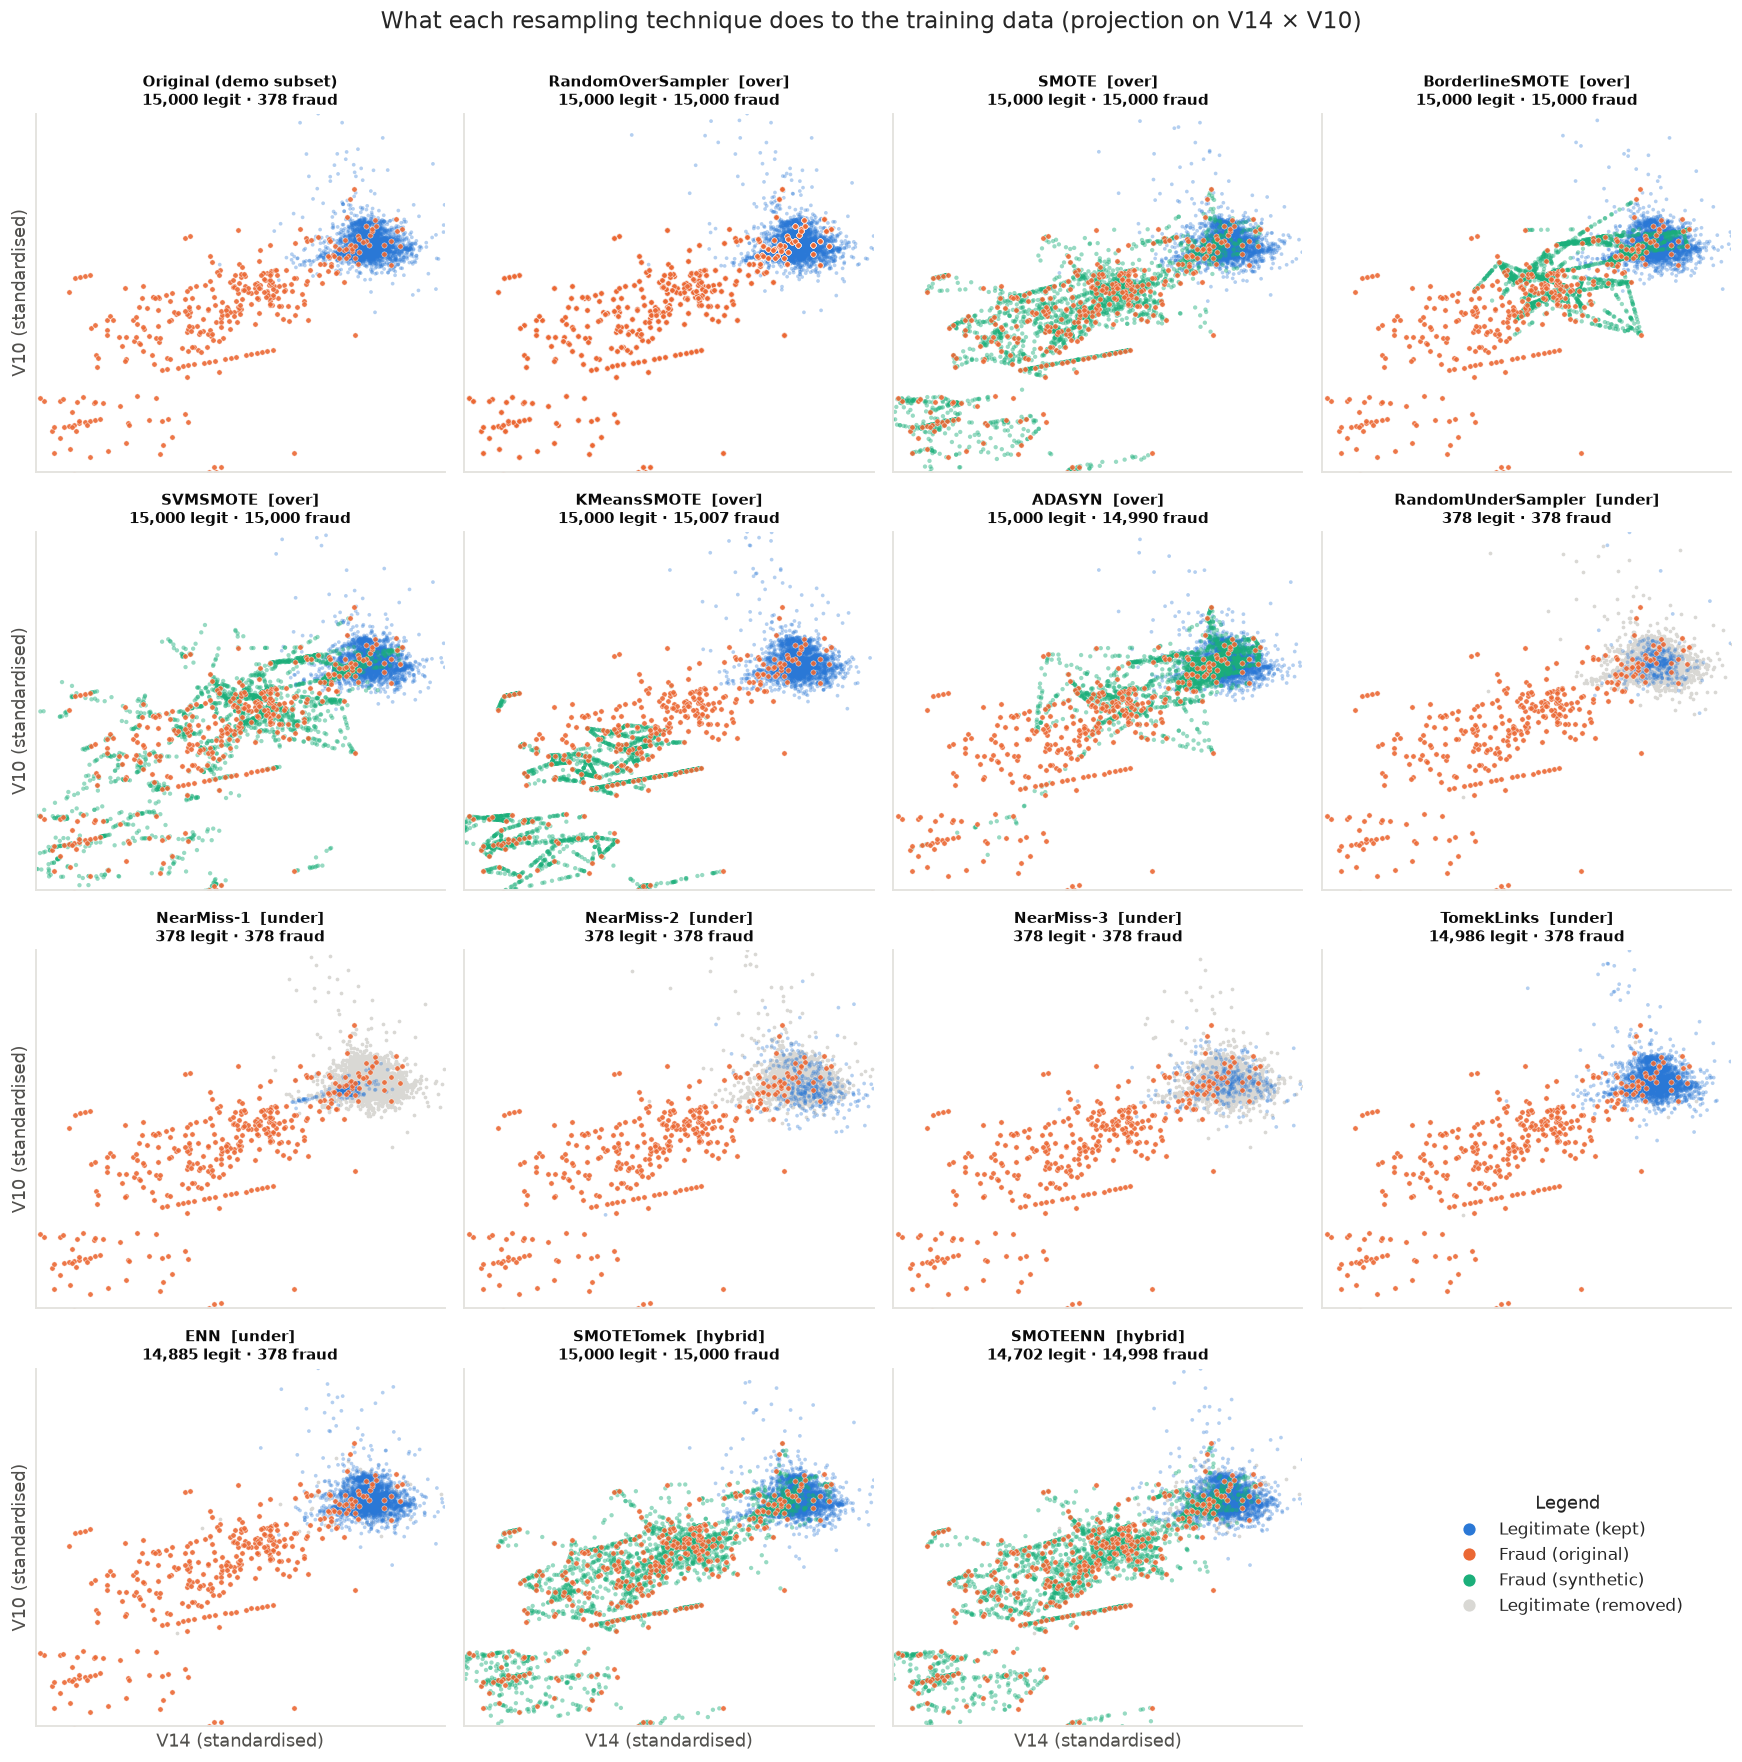

In [5]:
SYNTH_COLOR, REMOVED_COLOR = "#1baf7a", "#d9d8d4"
rng = np.random.default_rng(0)

def show(ax, X, y, synthetic=None, removed=None, title="", max_points=3000):
    def pick(mask):
        idx = np.flatnonzero(mask)
        return rng.choice(idx, max_points, replace=False) if len(idx) > max_points else idx
    if removed is not None and removed.any():
        i = pick(removed & (y_demo == 0))
        ax.scatter(X_demo[i, FX], X_demo[i, FY], s=6, c=REMOVED_COLOR, linewidths=0)
    synthetic = np.zeros(len(y), bool) if synthetic is None else synthetic
    for mask, color, size, alpha in [((y == 0), LEGIT_COLOR, 6, 0.35),
                                     ((y == 1) & synthetic, SYNTH_COLOR, 8, 0.45),
                                     ((y == 1) & ~synthetic, FRAUD_COLOR, 12, 0.9)]:
        i = pick(mask)
        ax.scatter(X[i, FX], X[i, FY], s=size, c=color, alpha=alpha,
                   edgecolors="white" if color == FRAUD_COLOR else "none", linewidths=0.3)
    ax.set_title(f"{title}\n{(y == 0).sum():,} legit · {(y == 1).sum():,} fraud", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

panels = ["Original"] + list(resampled)
fig, axes = plt.subplots(4, 4, figsize=(16, 16), sharex=True, sharey=True)
for ax, name in zip(axes.flat, panels):
    if name == "Original":
        show(ax, X_demo, y_demo, title="Original (demo subset)")
    else:
        X_res, y_res, synthetic, removed = resampled[name]
        show(ax, X_res, y_res, synthetic, removed, title=f"{name}  [{SAMPLERS[name].family}]")
for ax in axes.flat[len(panels):]:
    ax.axis("off")
axes[0, 0].set_xlim(np.percentile(X_demo[:, FX], 0.05), np.percentile(X_demo[:, FX], 99.95))
axes[0, 0].set_ylim(np.percentile(X_demo[:, FY], 0.05), np.percentile(X_demo[:, FY], 99.95))
for ax in axes[-1]:
    ax.set_xlabel("V14 (standardised)")
for ax in axes[:, 0]:
    ax.set_ylabel("V10 (standardised)")

from matplotlib.lines import Line2D
handles = [Line2D([], [], ls="", marker="o", color=c, ms=7, label=l) for c, l in
           [(LEGIT_COLOR, "Legitimate (kept)"), (FRAUD_COLOR, "Fraud (original)"),
            (SYNTH_COLOR, "Fraud (synthetic)"), (REMOVED_COLOR, "Legitimate (removed)")]]
fig.legend(handles=handles, loc="lower right", bbox_to_anchor=(0.97, 0.08), fontsize=11, title="Legend")
fig.suptitle("What each resampling technique does to the training data (projection on V14 × V10)",
             fontsize=15, y=1.0)
fig.tight_layout()
fig.savefig(FIGURES / "resampling_gallery.png", bbox_inches="tight", dpi=90)
plt.show()

### Reading the gallery

**Over-sampling** (fraud count raised to the number of legitimate transactions):

* **RandomOverSampler** looks identical to the original. It only adds *exact copies*, which are stacked
  on top of the existing frauds. The classifier sees the same points with more weight, which
  encourages it to memorise them (over-fitting).
* **SMOTE** fills the space *between* frauds with straight-line interpolations. The fraud region becomes a
  dense, continuous cloud. Some synthetic points land in the middle of the legitimate cluster,
  because they were interpolated between two frauds that are far apart.
* **Borderline-SMOTE** and **SVM-SMOTE** generate only from frauds near the legitimate cluster. The synthetic
  points concentrate along the border, which is where the classifier needs information.
* **ADASYN** pushes the generation even more toward the hardest frauds, those embedded in
  legitimate neighbourhoods. It reinforces the border but also invades the legitimate region.
* **K-Means-SMOTE** interpolates *within clusters*, so new samples stay closer to dense groups of frauds.

**Under-sampling**:

* **RandomUnderSampler** and **NearMiss** reduce the legitimate class to the size of the fraud class
  (a few hundred points). Most of the information about legitimate behaviour is thrown away.
  NearMiss-1/3 keep legitimate points *close to frauds*, so the class border is over-represented
  and the "normal" behaviour under-represented.
* **TomekLinks** and **ENN** remove only a handful of legitimate points that touch the fraud region.
  They *clean* the border but leave the imbalance practically unchanged.

**Hybrid**: **SMOTETomek** and **SMOTEENN** look like SMOTE, with the overlap at the border trimmed afterwards.
ENN is the more aggressive cleaner of the two.

## 5. Comparing the resulting datasets

In [6]:
summary = pd.DataFrame(rows).set_index("technique")
summary.style.format({"fraud share (%)": "{:.1f}", "time (s)": "{:.2f}",
                      "legit": "{:,}", "fraud": "{:,}", "synthetic frauds": "{:,}",
                      "duplicated frauds": "{:,}", "removed legit": "{:,}"}) \
    .bar(subset=["fraud share (%)"], color="#b7d3f6", vmin=0, vmax=100)

,family,legit,fraud,fraud share (%),synthetic frauds,duplicated frauds,removed legit,time (s)
technique,,,,,,,,
RandomOverSampler,over,"15,000","15,000",50.0,0,"14,622",0,0.01
SMOTE,over,"15,000","15,000",50.0,"14,622",0,0,0.03
BorderlineSMOTE,over,"15,000","15,000",50.0,"14,622",0,0,0.02
SVMSMOTE,over,"15,000","15,000",50.0,"14,622",0,0,0.38
KMeansSMOTE,over,"15,000","15,007",50.0,"14,629",0,0,0.16
ADASYN,over,"15,000","14,990",50.0,"14,612",0,0,0.01
RandomUnderSampler,under,378,378,50.0,0,0,"14,622",0.00
NearMiss-1,under,378,378,50.0,0,0,"14,622",0.02
NearMiss-2,under,378,378,50.0,0,0,"14,622",0.09


The table makes the differences concrete:

* Over-sampling and the hybrids end close to **50 % fraud**. The training set roughly *doubles* in size,
  which makes every model slower to train. On the full training set (≈ 227 000 rows) that means
  ≈ 450 000 rows.
* Random under-sampling and NearMiss also reach 50 %, but with a **tiny** training set (≈ 2 × 380 rows on the
  full data). Training is instantaneous, but most legitimate examples are discarded.
* Tomek Links and ENN keep the original imbalance. They are cleaning steps rather than balancing steps.
* The neighbour-based methods (SVM-SMOTE, Tomek, ENN and the hybrids) are the slowest: on the full
  training set they take from tens of seconds to a few minutes *per fold*.

## 6. Strengths and weaknesses of each family

| Family | Strengths | Weaknesses |
|---|---|---|
| Random over-sampling | Simple, no information loss | Exact duplicates → over-fitting; larger training set |
| SMOTE & variants | Synthetic diversity, smoother fraud region | May create implausible frauds in overlapping regions; larger training set; sensitive to scaling and to `k` |
| Random under-sampling | Very fast, tiny training set | Throws away > 99 % of legitimate data → many false alarms |
| NearMiss | Keeps informative points near the border | Distorts the legitimate distribution; very sensitive to noise |
| Tomek / ENN | Clean noisy borders, keep the real data | Barely change the imbalance on their own |
| Hybrid | Combine balance and cleaning | Slowest; inherit SMOTE's assumptions |
| Class weights | No data modification, no extra cost | Not available for every model (e.g. KNN) |

What all these techniques have in common is that they **move the decision threshold** of the
classifier toward the minority class. They usually raise **recall** at the cost of **precision**.
Whether that is a good trade, and which technique does it best for which model, is an empirical
question.

➡️ **Next:** [03 · Benchmark](03_benchmark.ipynb) compares all strategies with a leakage-free protocol.